In [1]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import pandas as pd


data = pd.read_csv('candy-data.csv')
print(data.head())

data_processed = data.copy()

  competitorname  chocolate  fruity  caramel  peanutyalmondy  nougat  \
0      100 Grand          1       0        1               0       0   
1   3 Musketeers          1       0        0               0       1   
2       One dime          0       0        0               0       0   
3    One quarter          0       0        0               0       0   
4      Air Heads          0       1        0               0       0   

   crispedricewafer  hard  bar  pluribus  sugarpercent  pricepercent  \
0                 1     0    1         0         0.732         0.860   
1                 0     0    1         0         0.604         0.511   
2                 0     0    0         0         0.011         0.116   
3                 0     0    0         0         0.011         0.511   
4                 0     0    0         0         0.906         0.511   

   winpercent  
0   66.971725  
1   67.602936  
2   32.261086  
3   46.116505  
4   52.341465  


Данные содержат следующие поля:

шоколад: содержит ли продукт шоколад?
фруктовый: с фруктовым вкусом?
карамель: есть ли в конфетах карамель?
арахисминдаль: содержит ли продукт арахис, арахисовую пасту или миндаль?
нуга: содержит ли продукт нугу?
хрустящие рисовые вафли: содержит ли продукт хрустящий рис, вафли или печенье?
твердые: это твердые конфеты?
батончик: это шоколадный батончик?
pluribus: одна из многих конфет в пакете или коробке?
sugarpercent: процентное содержание сахара в наборе данных.
pricepercent: процентное содержание цены за единицу товара по сравнению с остальным набором.
winpercent: общий процент побед по результатам 269 000 матчей.


Обработка данных

In [8]:
competitorname_mapping = {name: idx for idx, name in enumerate(data_processed['competitorname'].unique())}
data_processed['competitorname'] = data_processed['competitorname'].map(competitorname_mapping)
print("\nMapping названий конфет:")
print(competitorname_mapping)


Mapping названий конфет:
{'100 Grand': 0, '3 Musketeers': 1, 'One dime': 2, 'One quarter': 3, 'Air Heads': 4, 'Almond Joy': 5, 'Baby Ruth': 6, 'Boston Baked Beans': 7, 'Candy Corn': 8, 'Caramel Apple Pops': 9, 'Charleston Chew': 10, 'Chewey Lemonhead Fruit Mix': 11, 'Chiclets': 12, 'Dots': 13, 'Dum Dums': 14, 'Fruit Chews': 15, 'Fun Dip': 16, 'Gobstopper': 17, 'Haribo Gold Bears': 18, 'Haribo Happy Cola': 19, 'Haribo Sour Bears': 20, 'Haribo Twin Snakes': 21, 'HersheyÕs Kisses': 22, 'HersheyÕs Krackel': 23, 'HersheyÕs Milk Chocolate': 24, 'HersheyÕs Special Dark': 25, 'Jawbusters': 26, 'Junior Mints': 27, 'Kit Kat': 28, 'Laffy Taffy': 29, 'Lemonhead': 30, 'Lifesavers big ring gummies': 31, 'Peanut butter M&MÕs': 32, 'M&MÕs': 33, 'Mike & Ike': 34, 'Milk Duds': 35, 'Milky Way': 36, 'Milky Way Midnight': 37, 'Milky Way Simply Caramel': 38, 'Mounds': 39, 'Mr Good Bar': 40, 'Nerds': 41, 'Nestle Butterfinger': 42, 'Nestle Crunch': 43, 'Nik L Nip': 44, 'Now & Later': 45, 'Payday': 46, 'Peanu

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Определяем признаки и целевую переменную
feature_columns = ['chocolate', 'fruity', 'caramel', 'peanutyalmondy', 'nougat', 
                   'crispedricewafer', 'hard', 'bar', 'pluribus', 'sugarpercent', 'pricepercent']
X = data_processed[feature_columns]
y = data_processed['winpercent']

# Разделяем на train и test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Масштабирование признаков
min_max_scaler = MinMaxScaler()
X_train_scaled = min_max_scaler.fit_transform(X_train)
X_test_scaled = min_max_scaler.transform(X_test)

Визуализация данных

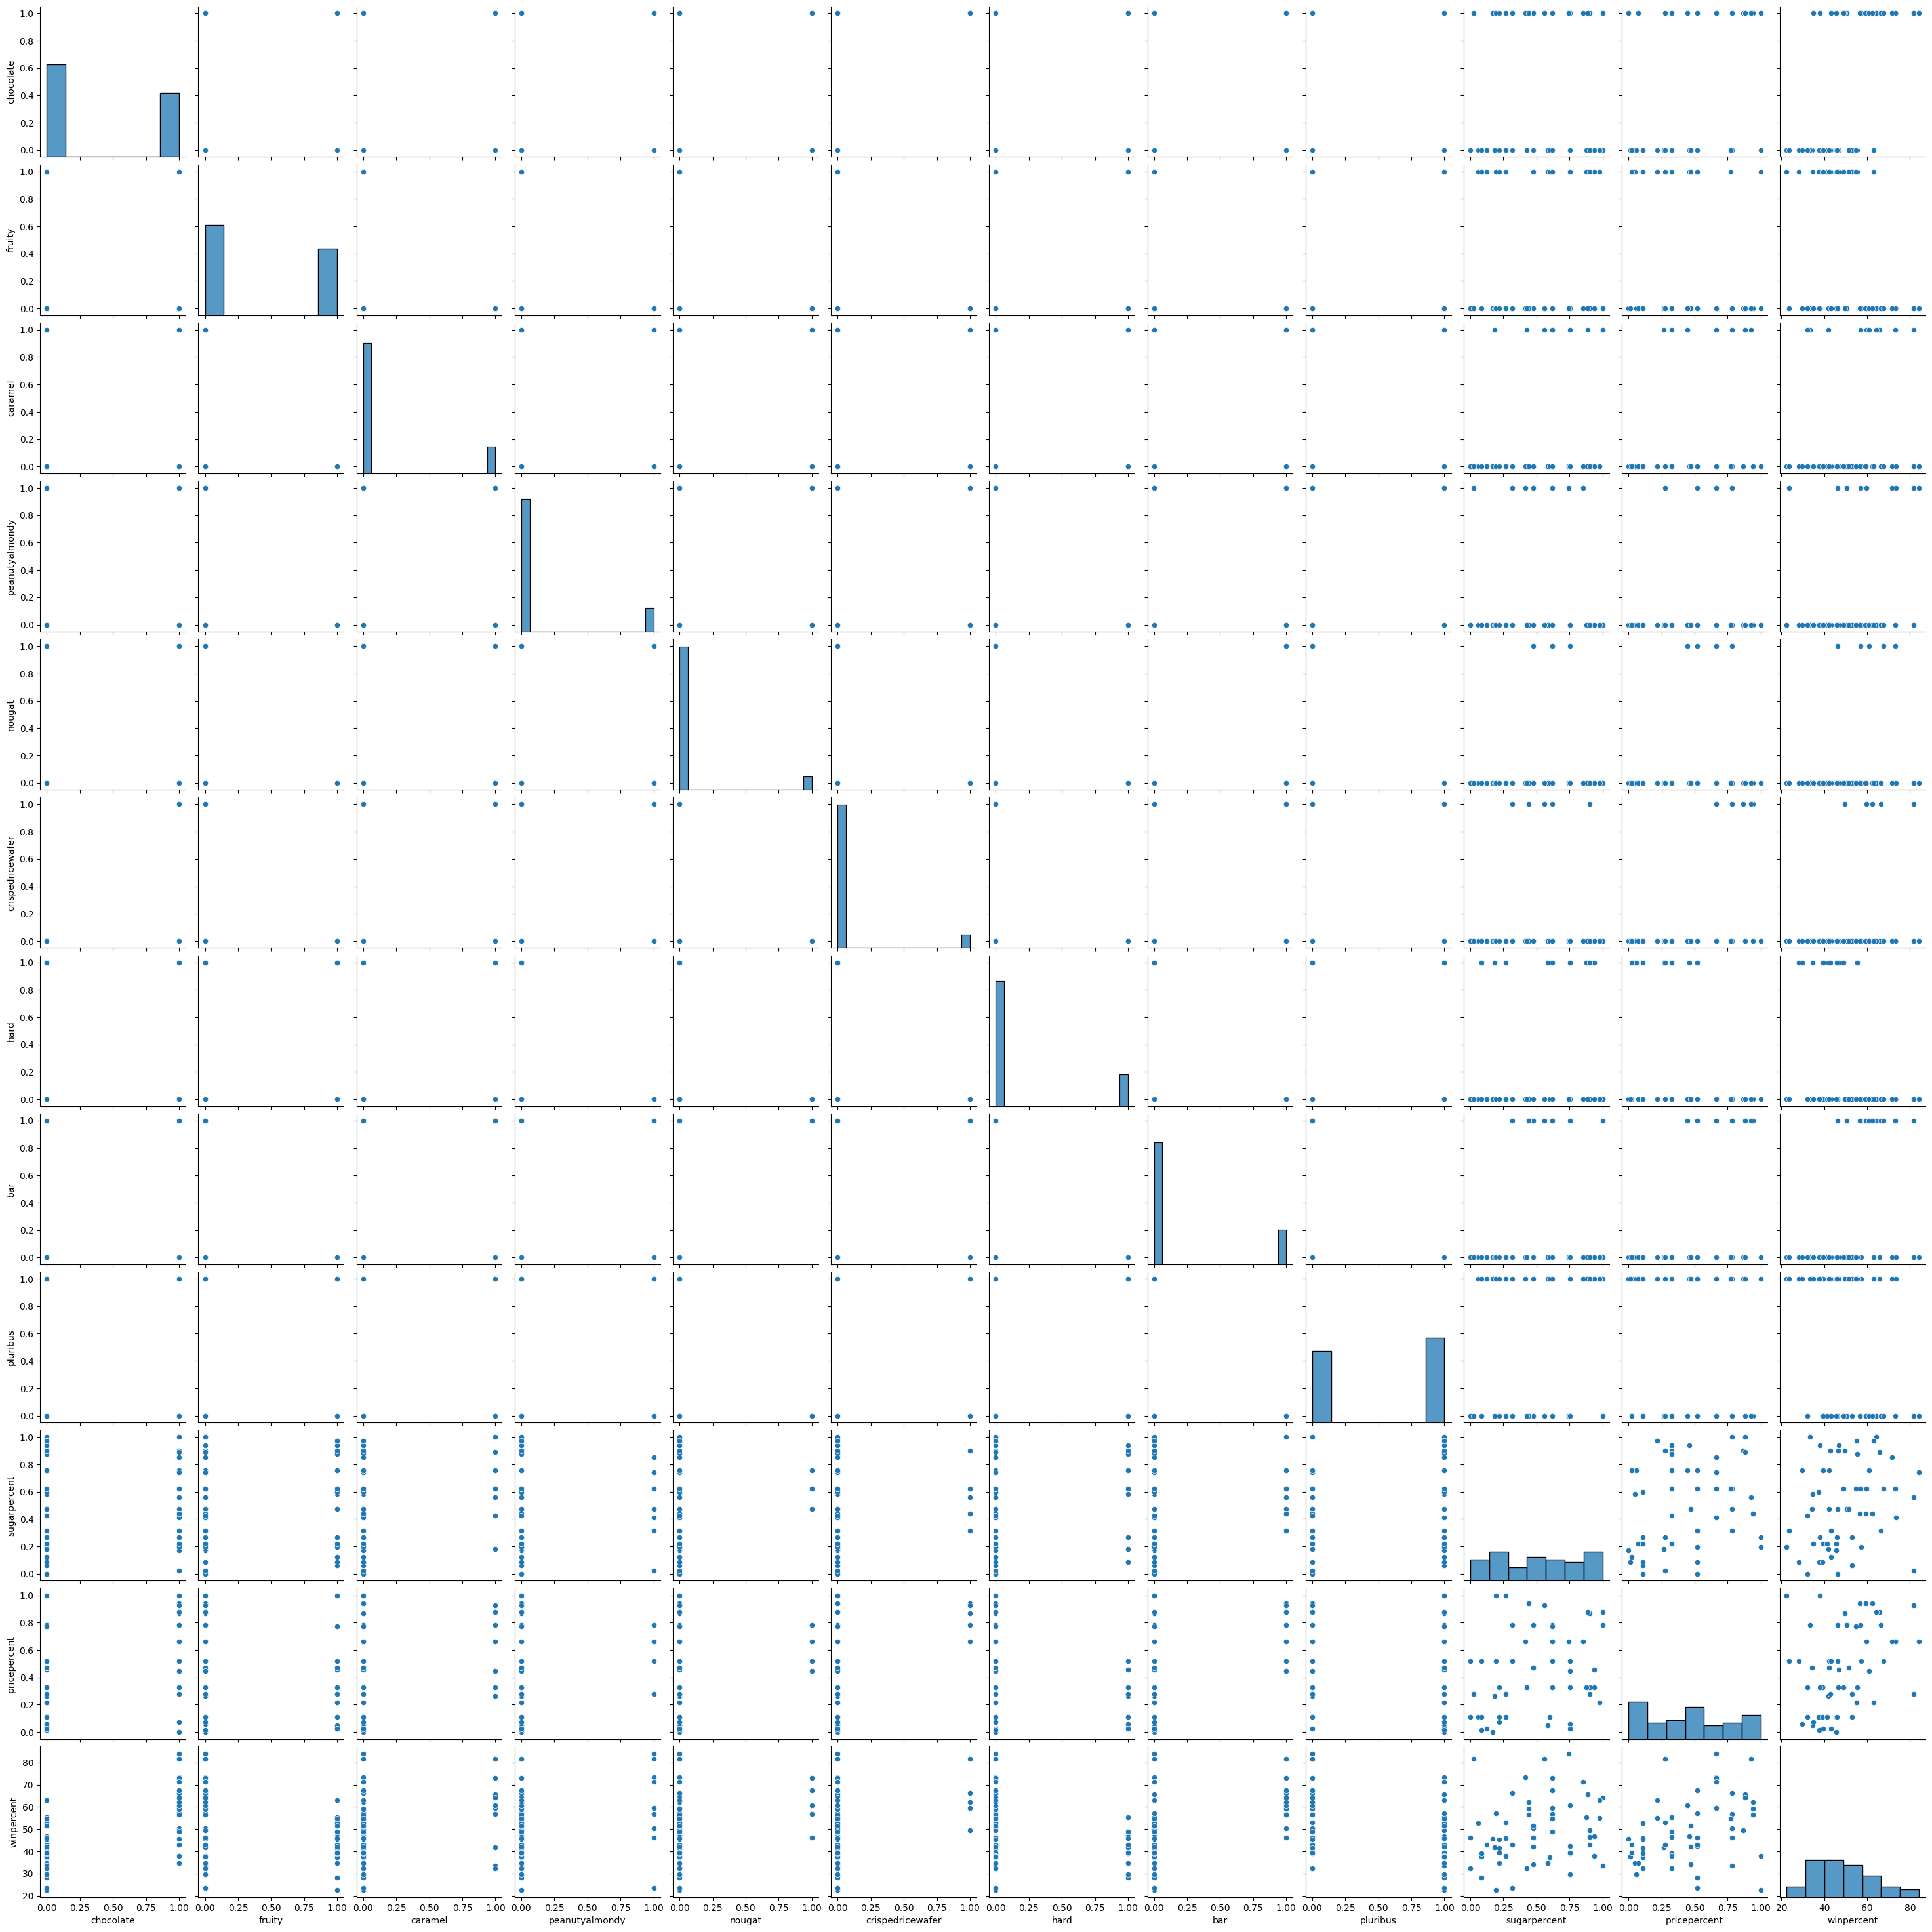

In [13]:
# DataFrame для визуализации с масштабированными данными
viz_df = pd.DataFrame(X_train_scaled, columns=feature_columns)
viz_df['winpercent'] = y_train.values

# Pairplot

%matplotlib inline

#sns.pairplot(data)
sns.pairplot(viz_df)
plt.show()


Визуализация матрицы корреляции

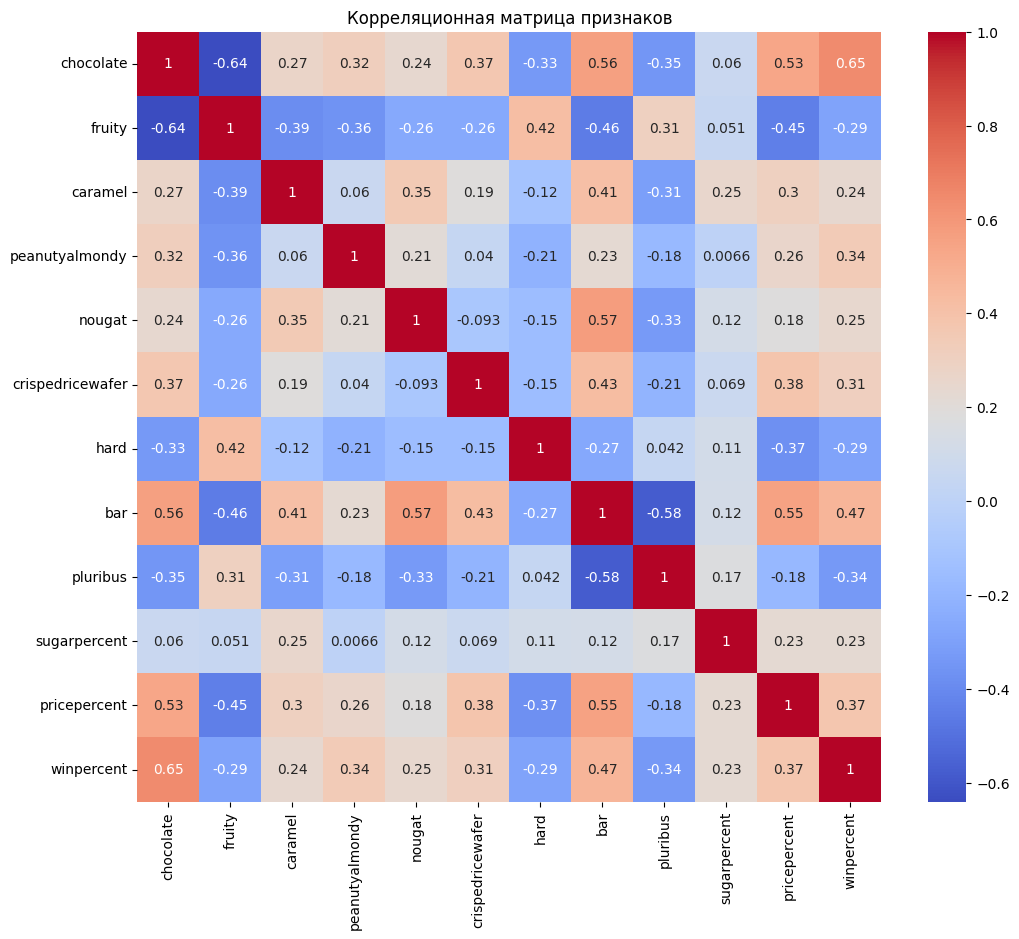

In [14]:
# Heatmap корреляций
plt.figure(figsize=(12, 10))
sns.heatmap(viz_df.corr(), annot=True, annot_kws={'size': 10}, cmap='coolwarm')
plt.title('Корреляционная матрица признаков')
plt.show()

Создание тензоров

In [16]:
import numpy as np

X_train_tensor = torch.from_numpy(X_train_scaled.astype(np.float32))
y_train_tensor = torch.from_numpy(y_train.values.astype(np.float32))

X_test_tensor = torch.from_numpy(X_test_scaled.astype(np.float32))
y_test_tensor = torch.from_numpy(y_test.values.astype(np.float32))

print("\nРазмерности тензоров:")
print(f"X_train_tensor shape: {X_train_tensor.shape}")
print(f"y_train_tensor shape: {y_train_tensor.shape}")
print(f"X_test_tensor shape: {X_test_tensor.shape}")
print(f"y_test_tensor shape: {y_test_tensor.shape}")


Размерности тензоров:
X_train_tensor shape: torch.Size([59, 11])
y_train_tensor shape: torch.Size([59])
X_test_tensor shape: torch.Size([26, 11])
y_test_tensor shape: torch.Size([26])


Разбиваем датасет на пакеты.

In [17]:
from torch.utils.data import TensorDataset, DataLoader


train_ds = TensorDataset(X_train_tensor, y_train_tensor)
test_ds = TensorDataset(X_train_tensor, y_train_tensor)

BATCH_SIZE = 32
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)

Создание экземпляра многослойного перцептрона

In [18]:
from torch import nn

model = nn.Sequential(
    nn.Linear(11, 256),
    nn.ReLU(),
    nn.Linear(256,128),
    nn.ReLU(),
    nn.Linear(128,64),
    nn.ReLU(),
    nn.Linear(64, 1),
)
print(model)

Sequential(
  (0): Linear(in_features=11, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=64, bias=True)
  (5): ReLU()
  (6): Linear(in_features=64, out_features=1, bias=True)
)


Определение функции потерь

In [19]:
criterion = nn.MSELoss()

In [20]:
LEARNING_RATE =1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [21]:
EPOCHS = 3000
losses = []

for epoch in range(EPOCHS):
    running_loss = 0
    for it, (x, y) in enumerate(train_dl):
        optimizer.zero_grad()
        
        outp = model(x)  # outp имеет размер [batch_size, 1]
        
        # размерность для функции потерь
        # сжимаем выход
        loss = criterion(outp.squeeze(), y)
        # loss = criterion(outp, y.unsqueeze(1))  # y.unsqueeze(1) -> [batch_size, 1]
        
        running_loss += loss.item()
        loss.backward()
        optimizer.step()
    
    # Выводим результат каждой эпохи (или каждые N эпох)
    avg_loss = running_loss / len(train_dl)
    losses.append(avg_loss)
    if epoch % 300 == 0:
        print(f"Epoch {epoch} - Training loss: {avg_loss:.6f}")

print(f"\nПоследняя потеря: {losses[-1]:.6f}")


Epoch 0 - Training loss: 2667.493896
Epoch 300 - Training loss: 26.125520
Epoch 600 - Training loss: 17.292726
Epoch 900 - Training loss: 12.029356
Epoch 1200 - Training loss: 8.410580
Epoch 1500 - Training loss: 3.495250
Epoch 1800 - Training loss: 2.469388
Epoch 2100 - Training loss: 1.847847
Epoch 2400 - Training loss: 2.111351
Epoch 2700 - Training loss: 1.763003

Последняя потеря: 1.725344


Построение ошибки обучения

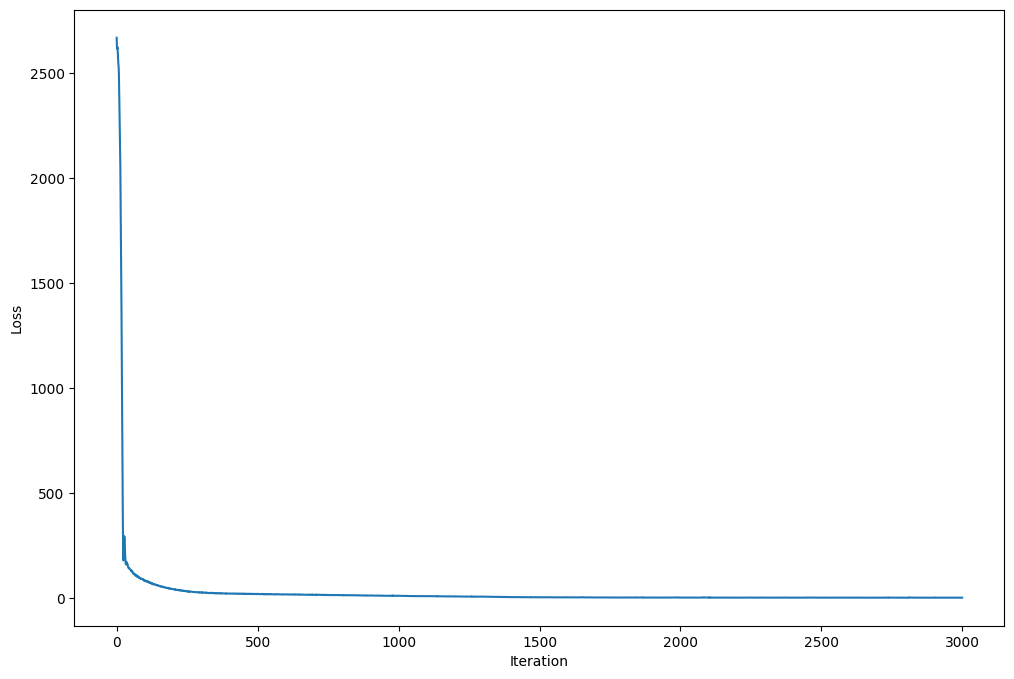

In [22]:
from matplotlib import pyplot as plt

plt.figure(figsize=(12, 8))
plt.plot(range(len(losses)), losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

Работа с тестовой выборкой. Извлекаем из нее первый элемент.

In [23]:
x,y

(tensor([[0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 1.0000,
          0.8774, 0.3254],
         [0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 1.0000,
          0.0860, 0.5181],
         [0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.2191, 0.1088],
         [1.0000, 0.0000, 1.0000, 0.0000, 1.0000, 0.0000, 0.0000, 1.0000, 0.0000,
          0.7558, 0.4456],
         [1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 1.0000, 0.0000,
          0.3166, 0.7834],
         [1.0000, 0.0000, 1.0000, 0.0000, 0.0000, 1.0000, 0.0000, 1.0000, 0.0000,
          0.5608, 0.9275],
         [1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000,
          0.2683, 1.0000],
         [1.0000, 0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0241, 0.2777],
         [0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 1.0000,
          0.2683, 0.1088],
         [0.0000, 1

In [24]:
it = iter(test_ds)

In [25]:
x, y = next(it)

Отдаем этот элемент многослойному перцептрону.

In [26]:
with torch.no_grad():
  y_pred = model(x)

In [27]:
y_pred

tensor([50.1662])

In [28]:
abs(y - y_pred)

tensor([0.1813])

Оценим среднюю ошибку прогноза по всей тестовой выборке.

In [29]:
with torch.no_grad():
  outp = model(X_test_tensor)
Y_pred = torch.reshape(outp, (-1,))
print(torch.mean(torch.abs(Y_pred - y_test_tensor)))

tensor(11.9967)
